# Import libraries

In [1]:
import all_functions
from all_functions import *
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
import pytorch_lightning as pl
from scipy import linalg
from scipy.linalg import LinAlgWarning
from scipy.linalg import lu_factor, lu_solve, LinAlgError

# Load the causal graph

In [2]:
edge_index = load_graph(r'C:\Users\uig53331\OneDrive - Aumovio SE\Bureau\THESE\codes\GDN_PROJECT\notebooks\TEP Dataset\sim_dataset\Experiments_data_sampled_3min\graphs_xmv\graph_ngc_CL_q090\edge_index.pt')
list_dir = 'C:/Users/uig53331/OneDrive - Aumovio SE/Bureau/THESE/codes/GDN_PROJECT/notebooks/TEP Dataset/sim_dataset/list.txt'
var_list = get_var_list(list_dir)

# Model deployment & results

In [92]:
class Main():
    def __init__(self, train_config, env_config, debug=False):

        self.train_config = train_config
        self.env_config = env_config
        self.datestr = None

        #train_orig = pd.read_csv('.../train.csv', sep=',', index_col=0)
        #test_orig  = pd.read_csv('.../test.csv', sep=',', index_col=0)
        train_orig = pd.read_csv(r'C:\Users\uig53331\OneDrive - Aumovio SE\Bureau\THESE\codes\GDN_PROJECT\notebooks\TEP Dataset\sim_dataset\datasets_sampled_3min\train_7days_xmv_norm.csv', sep=',', index_col=0)
        test_orig  = pd.read_csv(f'C:/Users/uig53331/OneDrive - Aumovio SE/Bureau/THESE/codes/GDN_PROJECT/notebooks/TEP Dataset/sim_dataset/datasets_sampled_3min/test_2days_idv14_xmv_norm.csv', sep=',', index_col=0)

        self.train = train_orig.copy()
        self.test  = test_orig.copy()
        
        if 'attack' in self.train.columns:
            train = self.train.drop(columns=['attack'])

        self.var_map = var_list
        
        set_device(env_config['device'])
        self.device = get_device()
        
        edge_index_sets = []
        self.edge_index = edge_index
        edge_index_sets.append(self.edge_index)
        
        train_dataset_indata = construct_data(self.train, var_list, labels=0)
        test_dataset_indata  = construct_data(self.test, var_list, labels=self.test.attack.tolist())

        cfg = {'slide_win': train_config['slide_win'],
               'slide_stride': train_config['slide_stride'],}

        train_dataset = TimeDataset(train_dataset_indata, self.edge_index, mode='train', config=cfg)
        test_dataset  = TimeDataset(test_dataset_indata, self.edge_index, mode='test', config=cfg)

        train_dataloader, val_dataloader = self.get_loaders(train_dataset, train_config['seed'], train_config['batch'], val_ratio = train_config['val_ratio'])
        
        self.train_dataset = train_dataset
        self.test_dataset = test_dataset
        
        self.train_dataloader = train_dataloader
        self.val_dataloader = val_dataloader
        self.test_dataloader = DataLoader(test_dataset, batch_size=train_config['batch'], shuffle=False, num_workers=0)
        self.model = normalModel(edge_index_sets, 
                                 len(var_list), 
                                dim=train_config['dim'], 
                                input_dim=train_config['slide_win'],
                                out_layer_num=train_config['out_layer_num'],
                                out_layer_inter_dim=train_config['out_layer_inter_dim']).to(self.device)

    def get_save_path(self):

        dir_path = self.env_config['save_path']
        
        if self.datestr is None:
            now = datetime.now()
            self.datestr = now.strftime('%m-%d-%H_%M_%S')
        datestr = self.datestr          

        paths = [f'{dir_path}/pretrained/best_{datestr}.pt', 
                 f'{dir_path}/results/{datestr}.csv']

        for path in paths:
            dirname = os.path.dirname(path)
            Path(dirname).mkdir(parents=True, exist_ok=True)

        return paths

    def run(self, target_tick_ppr, q_lo, q_hi, max_iter, tol, k):
        if len(self.env_config['load_model_path']) > 0:
            model_save_path = self.env_config['load_model_path']
            
        else:
            model_save_path = self.get_save_path()[0]

            self.train_log = all_functions.train(self.model, model_save_path, 
                config = self.train_config,
                train_dataloader=self.train_dataloader,
                val_dataloader=self.val_dataloader,
                train_dataset=self.train_dataset)

        self.model.load_state_dict(torch.load(model_save_path, map_location=self.device))        
        best_model = self.model.to(self.device)
        
        _, self.test_result = test(best_model, self.test_dataloader)
        val_loss, self.val_result = test(best_model, self.val_dataloader)
        print('val_loss:', val_loss)

        self.get_score(self.test_result, self.val_result, target_tick_ppr, q_lo, q_hi, max_iter, tol, k)


    def get_loaders(self, train_dataset, seed, batch, val_ratio=0.1):
        dataset_len = int(len(train_dataset))
        train_use_len = int(dataset_len * (1 - val_ratio))
        val_use_len = int(dataset_len * val_ratio)
        
        '''random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)'''
        val_start_index = random.randrange(train_use_len)
        print(val_start_index)
        indices = torch.arange(dataset_len)
        train_sub_indices = torch.cat([indices[:val_start_index], indices[val_start_index+val_use_len:]])
        val_sub_indices = indices[val_start_index:val_start_index+val_use_len]
        
        train_subset = Subset(train_dataset, train_sub_indices)
        val_subset = Subset(train_dataset, val_sub_indices)

        g =torch.Generator()
        g.manual_seed(seed)
        
        train_dataloader = DataLoader(train_subset, batch_size=batch, shuffle=True, generator=g, num_workers=0)
        val_dataloader = DataLoader(val_subset, batch_size=batch, shuffle=False, generator=g,  num_workers=0)

        return train_dataloader, val_dataloader


    def get_score(self, test_result, val_result, target_tick_ppr, q_lo, q_hi, max_iter, tol, k):

        np_test_result = np.array(test_result)
        np_val_result = np.array(val_result)
        test_labels = np_test_result[2, :, 0].tolist()
        
        self.gt_labels = test_labels
        self.test_pred_scores, self.val_pred_scores = get_full_pred_errors(test_result, val_result)
    
        self.sensor_thresholds, self.pred_sensor_labels = get_sensor_anomality_quantile_target_ppr(test_labels, test_result, val_result, target_tick_ppr, q_lo, q_hi, max_iter, tol)
        self.pred_val_sensor_labels = np.array([(np.asarray(self.val_pred_scores[s]).reshape(-1) > self.sensor_thresholds[s]).astype(int)
            for s in range(len(self.sensor_thresholds))
        ])
        
        result_info = get_test_performance_quantile_target_ppr(test_labels, test_result, val_result, target_tick_ppr,q_lo, q_hi, max_iter, tol, k)
        self.result_info = result_info
        
        print('=========================** Result of Timetick Anomaly Detection **============================\n')
        print(f'Macro-F1 score: {result_info[0]}')
        print(f'MCC score: {result_info[1]}\n')
        print(result_info[2])
        return result_info


    def predict_new_data(self, new_data, batch_size=None):
        """
        Run inference on new, unseen data with the already-trained model.
        new_data: a CSV path, or an already-loaded pandas DataFrame.
        Call only after self.run() has loaded the trained weights.
        """
        new_df = pd.read_csv(new_data, sep=',', index_col=0) if isinstance(new_data, str) else new_data

        # labels aren't used in the forward pass, only for scoring later,
        # so dummy zeros are fine if this data has no ground-truth 'attack' column
        labels = new_df['attack'].tolist() if 'attack' in new_df.columns else 0

        new_indata = construct_data(new_df, self.feature_map, labels=labels)

        cfg = {
        'slide_win': self.train_config['slide_win'],
        'slide_stride': self.train_config['slide_stride'],
        }

        new_dataset = TimeDataset(new_indata, self.edge_index, mode='test', config=cfg)
        new_dataloader = DataLoader(new_dataset, batch_size=batch_size or self.train_config['batch'], shuffle=False, num_workers=0,)


        self.model.eval()
        _, new_result = test(self.model, new_dataloader)
        return new_result





if __name__ == "__main__":
    
    sys.argv = [''] 
    def set_seed(seed):
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        pl.seed_everything(seed, workers=True)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        os.environ['PYTHONHASHSEED'] = str(seed)
        
    parser = argparse.ArgumentParser()
    parser.add_argument('-batch', help='batch size', type = int, default=16)
    parser.add_argument('-epoch', help='train epoch', type = int, default=100)
    parser.add_argument('-slide_win', help='slide window size', type = int, default=30)
    parser.add_argument('-dim', help='node dimension', type = int, default=64)
    parser.add_argument('-slide_stride', help='slide stride', type = int, default=1)
    parser.add_argument('-save_path', help='save trained model', type = str, default=r'C:\Users\uig53331\OneDrive - Aumovio SE\Bureau\THESE\codes\XS2C\pretrained')
    parser.add_argument('-device', help='cuda / cpu', type = str, default='cuda')
    parser.add_argument('-random_seed', help='random seed', type = int, default=42)
    parser.add_argument('-out_layer_num', help='output size ', type = int, default=1)
    parser.add_argument('-out_layer_inter_dim', help='hidden dim of forecast layer', type = int, default=256)
    parser.add_argument('-decay', help='decay', type = float, default=0)
    parser.add_argument('-val_ratio', help='validation ratio', type = float, default=0.1)
    parser.add_argument('-lr', help='learning rate', type = float, default=0.001)
    parser.add_argument('-load_model_path', help='load pretrained model path', type = str, default=r'C:\Users\uig53331\OneDrive - Aumovio SE\Bureau\THESE\codes\XS2C\best_models\tep_best_model.pt')
    #parser.add_argument('-load_model_path', help='load pretrained model path', type = str, default=r'C:\Users\uig53331\OneDrive - Aumovio SE\Bureau\THESE\codes\XS2C\pretrained\pretrained\best_05-26-13_34_19.pt') # best model for graph augmented
    args = parser.parse_args()
    
    train_config = {
        'batch': args.batch,
        'epoch': args.epoch,
        'slide_win': args.slide_win,
        'dim': args.dim,
        'slide_stride': args.slide_stride,
        'seed': args.random_seed,
        'out_layer_num': args.out_layer_num,
        'out_layer_inter_dim': args.out_layer_inter_dim,
        'decay': args.decay,
        'val_ratio': args.val_ratio,
        'lr': args.lr}

    set_seed(train_config['seed'])

    env_config={
        'save_path': args.save_path,
        'device': args.device,
        'load_model_path': args.load_model_path
    }
    

    # 1. Initialize and run the model to generate test_results
    normal_main = Main(train_config, env_config, debug=False)
    normal_main.run(k=2, target_tick_ppr=0.09, q_lo=0.90, q_hi=0.9999, max_iter=25, tol=0.0001)

    # 1. Get the raw original labels and test results
    test_result = normal_main.test_result
    val_result = normal_main.val_result
    np_test_result = np.array(test_result)
    original_labels = np_test_result[2, :, 0].tolist()

    # 2. CALCULATE THRESHOLDS FIRST (using the original labels to find the baselines)
    sensor_thresholds, _ = get_sensor_anomality_quantile_target_ppr(
        original_labels, test_result, val_result,
        target_tick_ppr=0.09, q_lo=0.90, q_hi=0.9999, max_iter=25, tol=0.0001
    )

    series = np.asarray(test_result)
    val_series = np.asarray(val_result)
    a = np.abs(series[0] - series[1])
    b = np.abs(val_series[0]- val_series[1])

Seed set to 42


2619
val_loss: 0.012975974673671382
[ADAPTIVE-QUANTILE] target_tick_ppr=0.0900 -> q*=0.99707, val_tick_ppr≈0.08408
[ADAPTIVE-QUANTILE] target_tick_ppr=0.0900 -> q*=0.99707, val_tick_ppr≈0.08408
=========================** Result of Timetick Anomaly Detection **============================

Macro-F1 score: 0.9574549846288977
MCC score: 0.9170845344937776

              precision    recall  f1-score   support

           0       0.88      0.98      0.93       130
           1       1.00      0.98      0.99       800

    accuracy                           0.98       930
   macro avg       0.94      0.98      0.96       930
weighted avg       0.98      0.98      0.98       930

[ADAPTIVE-QUANTILE] target_tick_ppr=0.0900 -> q*=0.99707, val_tick_ppr≈0.08408


In [93]:
import warnings
import numpy as np
import pandas as pd

from scipy.linalg import LinAlgWarning
from scipy.optimize import minimize
from sklearn.metrics import f1_score, matthews_corrcoef


# ============================================================
# 1. FOLDED-NORMAL LOG-DENSITY
# ============================================================

def folded_normal_logpdf(x, mu, sigma):
    """
    Log-density of |N(mu, sigma^2)|.

    x may be a matrix.
    mu and sigma may be sensor-wise vectors.
    """

    x = np.asarray(x, dtype=float)
    mu = np.asarray(mu, dtype=float)

    sigma = np.maximum(
        np.asarray(sigma, dtype=float),
        1e-12,
    )

    z_positive = (
        -0.5 * ((x - mu) / sigma) ** 2
    )

    z_negative = (
        -0.5 * ((x + mu) / sigma) ** 2
    )

    return (
        np.logaddexp(
            z_positive,
            z_negative,
        )
        - np.log(sigma)
        - 0.5 * np.log(2.0 * np.pi)
    )


# ============================================================
# 2. SENSOR-WISE FOLDED-NORMAL MLE
# ============================================================

import numpy as np

from scipy.optimize import minimize
from scipy.special import logsumexp


def fit_folded_normal_mle(
    validation_errors,
    sigma_floor=1e-8,
    max_iter=2000,
):
    """
    Fit one folded-normal distribution per sensor by maximum
    likelihood.

    Parameters
    ----------
    validation_errors : array-like, shape (n_steps, n_sensors)
        Non-negative absolute validation errors.

    sigma_floor : float
        Smallest allowed sigma value.

    max_iter : int
        Maximum number of optimizer iterations.

    Returns
    -------
    mu_hat : ndarray, shape (n_sensors,)
        Estimated latent Gaussian location parameters.

    sigma_hat : ndarray, shape (n_sensors,)
        Estimated latent Gaussian scale parameters.

    success_flags : ndarray, shape (n_sensors,)
        Boolean optimization-success flags.
    """

    validation_errors = np.asarray(
        validation_errors,
        dtype=float,
    )

    if validation_errors.ndim != 2:
        raise ValueError(
            "validation_errors must have shape "
            "(n_steps, n_sensors). "
            f"Received shape: {validation_errors.shape}"
        )

    if np.any(~np.isfinite(validation_errors)):
        raise ValueError(
            "validation_errors contains NaN or infinite values."
        )

    if np.any(validation_errors < 0.0):
        minimum_value = float(
            np.min(validation_errors)
        )

        raise ValueError(
            "Folded-normal observations must be non-negative. "
            f"Minimum observed value: {minimum_value}"
        )

    number_of_sensors = validation_errors.shape[1]

    mu_hat = np.full(
        number_of_sensors,
        np.nan,
        dtype=float,
    )

    sigma_hat = np.full(
        number_of_sensors,
        np.nan,
        dtype=float,
    )

    success_flags = np.zeros(
        number_of_sensors,
        dtype=bool,
    )

    sqrt_two_pi_log = 0.5 * np.log(
        2.0 * np.pi
    )

    for sensor in range(number_of_sensors):

        observations = validation_errors[
            :,
            sensor,
        ]

        observations = observations[
            np.isfinite(observations)
        ]

        if observations.size < 2:
            raise ValueError(
                f"Sensor {sensor}: fewer than two finite "
                "validation observations."
            )

        sample_mean = float(
            np.mean(observations)
        )

        sample_variance = float(
            np.var(
                observations,
                ddof=0,
            )
        )

        sample_standard_deviation = float(
            np.sqrt(
                max(
                    sample_variance,
                    sigma_floor ** 2,
                )
            )
        )

        root_mean_square = float(
            np.sqrt(
                np.mean(
                    observations ** 2
                )
            )
        )

        # ----------------------------------------------------
        # Folded-normal negative log-likelihood
        #
        # Optimization parameters:
        #   parameter_vector[0] = log(mu + epsilon)
        #   parameter_vector[1] = log(sigma)
        #
        # Exponentiating guarantees:
        #   mu >= 0
        #   sigma > 0
        # ----------------------------------------------------

        def negative_log_likelihood(
            parameter_vector,
        ):
            parameter_vector = np.asarray(
                parameter_vector,
                dtype=float,
            ).reshape(-1)

            if parameter_vector.size != 2:
                return float(
                    np.inf
                )

            log_mu = float(
                parameter_vector[0]
            )

            log_sigma = float(
                parameter_vector[1]
            )

            mu = float(
                np.exp(log_mu)
            )

            sigma = float(
                np.exp(log_sigma)
            )

            if (
                not np.isfinite(mu)
                or not np.isfinite(sigma)
                or sigma <= sigma_floor
            ):
                return float(
                    np.inf
                )

            denominator = (
                2.0 * sigma ** 2
            )

            exponent_positive = -(
                (observations - mu) ** 2
            ) / denominator

            exponent_negative = -(
                (observations + mu) ** 2
            ) / denominator

            stacked_exponents = np.vstack(
                (
                    exponent_positive,
                    exponent_negative,
                )
            )

            log_density = (
                logsumexp(
                    stacked_exponents,
                    axis=0,
                )
                - np.log(sigma)
                - sqrt_two_pi_log
            )

            if np.any(
                ~np.isfinite(log_density)
            ):
                return float(
                    np.inf
                )

            # IMPORTANT:
            # scipy.optimize.minimize requires one scalar.
            negative_log_likelihood_value = -float(
                np.sum(log_density)
            )

            return negative_log_likelihood_value

        # ----------------------------------------------------
        # Multiple starting points
        #
        # Folded-normal likelihood can be difficult near
        # mu = 0, so several initial values are tested.
        # ----------------------------------------------------

        small_mu = max(
            sample_mean * 0.05,
            1e-6,
        )

        initial_candidates = [
            (
                small_mu,
                sample_standard_deviation,
            ),
            (
                max(sample_mean, 1e-6),
                sample_standard_deviation,
            ),
            (
                max(
                    0.5 * sample_mean,
                    1e-6,
                ),
                max(
                    root_mean_square,
                    sigma_floor,
                ),
            ),
            (
                max(
                    root_mean_square,
                    1e-6,
                ),
                max(
                    sample_standard_deviation,
                    sigma_floor,
                ),
            ),
        ]

        best_result = None
        best_objective = np.inf

        for initial_mu, initial_sigma in initial_candidates:

            initial_vector = np.array(
                [
                    np.log(
                        max(
                            float(initial_mu),
                            1e-12,
                        )
                    ),
                    np.log(
                        max(
                            float(initial_sigma),
                            sigma_floor * 10.0,
                        )
                    ),
                ],
                dtype=float,
            )

            result = minimize(
                negative_log_likelihood,
                x0=initial_vector,
                method="L-BFGS-B",
                bounds=[
                    (
                        np.log(1e-12),
                        np.log(
                            max(
                                root_mean_square * 100.0,
                                100.0,
                            )
                        ),
                    ),
                    (
                        np.log(sigma_floor),
                        np.log(
                            max(
                                root_mean_square * 100.0,
                                100.0,
                            )
                        ),
                    ),
                ],
                options={
                    "maxiter": int(max_iter),
                    "ftol": 1e-12,
                    "gtol": 1e-8,
                },
            )

            # result.fun should be scalar, but flattening makes
            # the check robust against accidental 1-element arrays.
            result_fun_array = np.asarray(
                result.fun,
                dtype=float,
            ).reshape(-1)

            if result_fun_array.size != 1:
                continue

            objective_value = float(
                result_fun_array[0]
            )

            optimizer_success = bool(
                np.asarray(
                    result.success
                ).reshape(-1)[0]
            )

            candidate_is_valid = bool(
                optimizer_success
                and np.isfinite(
                    objective_value
                )
                and np.asarray(
                    result.x
                ).size == 2
                and np.all(
                    np.isfinite(
                        result.x
                    )
                )
            )

            if (
                candidate_is_valid
                and objective_value
                < best_objective
            ):
                best_result = result
                best_objective = (
                    objective_value
                )

        if best_result is None:
            raise RuntimeError(
                f"Sensor {sensor}: folded-normal MLE failed "
                "for all initial values. "
                f"Sample mean={sample_mean:.8g}, "
                f"sample std={sample_standard_deviation:.8g}, "
                f"number of observations={observations.size}."
            )

        best_parameters = np.asarray(
            best_result.x,
            dtype=float,
        ).reshape(-1)

        estimated_mu = float(
            np.exp(
                best_parameters[0]
            )
        )

        estimated_sigma = float(
            np.exp(
                best_parameters[1]
            )
        )

        final_objective = float(
            negative_log_likelihood(
                best_parameters
            )
        )

        final_success = bool(
            np.isfinite(estimated_mu)
            and np.isfinite(estimated_sigma)
            and estimated_mu >= 0.0
            and estimated_sigma > sigma_floor
            and np.isfinite(
                final_objective
            )
        )

        if not final_success:
            raise RuntimeError(
                f"Sensor {sensor}: invalid folded-normal "
                "MLE result. "
                f"mu={estimated_mu}, "
                f"sigma={estimated_sigma}, "
                f"objective={final_objective}."
            )

        mu_hat[sensor] = estimated_mu
        sigma_hat[sensor] = estimated_sigma
        success_flags[sensor] = True

        print(
            f"Sensor {sensor:02d}: "
            f"mu_MLE={estimated_mu:.8f}, "
            f"sigma_MLE={estimated_sigma:.8f}, "
            f"NLL={final_objective:.6f}, "
            f"success={success_flags[sensor]}"
        )

    return (
        mu_hat,
        sigma_hat,
        success_flags,
    )

# ============================================================
# 3. LOG-LIKELIHOOD-RATIO INCREMENTS
# ============================================================

def compute_llr(
    errors,
    mu0,
    mu1,
    sigma,
):
    """
    Calculate sensor-wise folded-normal LLR increments:

        log f(x; mu1, sigma)
        -
        log f(x; mu0, sigma)
    """

    errors = np.asarray(
        errors,
        dtype=float,
    )

    log_changed = (
        folded_normal_logpdf(
            errors,
            mu1,
            sigma,
        )
    )

    log_normal = (
        folded_normal_logpdf(
            errors,
            mu0,
            sigma,
        )
    )

    return (
        log_changed
        - log_normal
    )


# ============================================================
# 4. VECTORIZED CUSUM FROM PRECOMPUTED INCREMENTS
# ============================================================

def cusum_from_increments(
    increments,
    thresholds=None,
    burn_in=30,
):
    """
    Run CUSUM using already-computed LLR increments.

    If thresholds=None, only S and G trajectories are computed.
    """

    increments = np.asarray(
        increments,
        dtype=float,
    )

    num_steps, num_sensors = (
        increments.shape
    )

    S = np.zeros(
        (num_steps, num_sensors)
    )

    G = np.zeros(
        (num_steps, num_sensors)
    )

    detection_times = np.full(
        num_sensors,
        np.nan,
    )

    change_points = np.full(
        num_sensors,
        np.nan,
    )

    detected = np.zeros(
        num_sensors,
        dtype=bool,
    )

    for t in range(
        burn_in,
        num_steps,
    ):

        if t == burn_in:
            previous_S = np.zeros(
                num_sensors
            )

            previous_G = np.zeros(
                num_sensors
            )

        else:
            previous_S = S[t - 1]
            previous_G = G[t - 1]

        S[t] = (
            previous_S
            + increments[t]
        )

        G[t] = np.maximum(
            0.0,
            previous_G
            + increments[t],
        )

        if thresholds is not None:

            triggers = (
                (G[t] > thresholds)
                & (~detected)
            )

            triggered_sensors = np.where(
                triggers
            )[0]

            for sensor in (
                triggered_sensors
            ):

                detection_times[
                    sensor
                ] = t

                change_points[
                    sensor
                ] = (
                    burn_in
                    + int(
                        np.argmin(
                            S[
                                burn_in:t + 1,
                                sensor,
                            ]
                        )
                    )
                )

                detected[sensor] = True

    return (
        detection_times,
        change_points,
        S,
        G,
    )


# ============================================================
# 5. HOCANIN ÖNERDİĞİ STATE-CONDITIONED MATRIX
# ============================================================

def state_conditioned_transition(
    validation_increments,
    threshold,
    num_states=10,
):
    """
    Build the transition matrix using:

        J_next = max(0, c_r + s_val)

    for every representative state c_r and every validation
    LLR increment.

    The discretization matches the thesis definition:

        w = h / (num_states - 0.5)

        bins = (k + 0.5) * w

        c_r = r * w
    """

    validation_increments = np.asarray(
        validation_increments,
        dtype=float,
    )

    validation_increments = (
        validation_increments[
            np.isfinite(
                validation_increments
            )
        ]
    )

    if validation_increments.size == 0:
        raise ValueError(
            "No valid validation increments."
        )

    w = threshold / (num_states - 0.5)

    bins = (
        np.arange(num_states) + 0.5
    ) * w

    representative_values = (
        np.arange(num_states, dtype=float)
        * w
    )

    representative_values[0] = 0.25 * w

    transition_matrix = np.zeros(
        (
            num_states + 1,
            num_states + 1,
        )
    )

    for state, c_r in enumerate(
        representative_values
    ):

        next_cusum = np.maximum(
            0.0,
            c_r
            + validation_increments,
        )

        next_states = np.digitize(
            next_cusum,
            bins,
            right=True,
        )

        counts = np.bincount(
            next_states,
            minlength=num_states + 1,
        )

        transition_matrix[state] = (
            counts
            / counts.sum()
        )

    # Absorbing alarm state.
    transition_matrix[-1, :] = 0.0
    transition_matrix[-1, -1] = 1.0

    return transition_matrix


# ============================================================
# 6. VALID FINITE ARL
# ============================================================

def calculate_finite_arl(
    transition_matrix,
    spectral_tolerance=1e-10,
    condition_limit=1e12,
):
    """
    Calculate ARL only when:

        - an alarm transition exists,
        - spectral radius of Q is below 1,
        - I-Q is not singular or ill-conditioned,
        - all ARL entries are finite and positive.
    """

    Q = transition_matrix[
        :-1,
        :-1,
    ]

    system_matrix = (
        np.eye(Q.shape[0])
        - Q
    )

    eigenvalues = np.linalg.eigvals(
        Q
    )

    spectral_radius = float(
        np.max(
            np.abs(eigenvalues)
        )
    )

    condition_number = float(
        np.linalg.cond(
            system_matrix
        )
    )

    alarm_probability_sum = float(
        transition_matrix[
            :-1,
            -1,
        ].sum()
    )

    matrix_is_valid = bool(
        alarm_probability_sum > 0.0
        and spectral_radius
        < 1.0 - spectral_tolerance
        and np.isfinite(
            condition_number
        )
        and condition_number
        < condition_limit
    )

    if not matrix_is_valid:

        return (
            np.inf,
            spectral_radius,
            condition_number,
            alarm_probability_sum,
        )

    try:

        with warnings.catch_warnings():

            warnings.simplefilter(
                "error",
                LinAlgWarning,
            )

            arl_vector = np.linalg.solve(
                system_matrix,
                np.ones(Q.shape[0]),
            )

        valid_solution = bool(
            np.all(
                np.isfinite(
                    arl_vector
                )
            )
            and np.all(
                arl_vector > 0.0
            )
        )

        if valid_solution:
            arl_state_0 = float(
                arl_vector[0]
            )
        else:
            arl_state_0 = np.inf

    except (
        np.linalg.LinAlgError,
        LinAlgWarning,
        ValueError,
    ):
        arl_state_0 = np.inf

    return (
        arl_state_0,
        spectral_radius,
        condition_number,
        alarm_probability_sum,
    )


# ============================================================
# 7. SENSOR-WISE THRESHOLD CALIBRATION
# ============================================================

def calibrate_cusum_thresholds(
    validation_increments,
    validation_cusum,
    target_arl=160,
    num_states=10,
    candidate_offsets=range(5, 40),
    fallback_factor=2.5,
    burn_in=30,
):
    """
    For every sensor:

    1. Start from max validation CUSUM.
    2. Test thresholds lower_bound + 5, ..., lower_bound + 39.
    3. Construct the state-conditioned Markov matrix.
    4. Select the first valid threshold with ARL >= target.
    5. Use fallback only if no valid threshold is found.
    """

    num_sensors = (
        validation_increments.shape[1]
    )

    lower_bounds = np.max(
        validation_cusum,
        axis=0,
    )

    selected_thresholds = np.zeros(
        num_sensors
    )

    diagnostic_rows = []

    for sensor in range(
        num_sensors
    ):

        chosen_threshold = None

        increments_sensor = (
            validation_increments[
                burn_in:,
                sensor,
            ]
        )

        for offset in (
            candidate_offsets
        ):

            threshold = float(
                lower_bounds[sensor]
                + offset
            )

            transition_matrix = (
                state_conditioned_transition(
                    validation_increments=(
                        increments_sensor
                    ),
                    threshold=threshold,
                    num_states=num_states,
                )
            )

            (
                arl0,
                spectral_radius,
                condition_number,
                alarm_probability_sum,
            ) = calculate_finite_arl(
                transition_matrix
            )

            target_pass = bool(
                np.isfinite(arl0)
                and arl0 >= target_arl
            )

            diagnostic_rows.append({
                "sensor": sensor,
                "threshold": threshold,
                "arl0": arl0,
                "spectral_radius":
                    spectral_radius,
                "condition_number":
                    condition_number,
                "alarm_probability_sum":
                    alarm_probability_sum,
                "target_pass":
                    target_pass,
            })

            if target_pass:
                chosen_threshold = threshold
                break

        if chosen_threshold is None:

            selected_thresholds[sensor] = (
                fallback_factor
                * lower_bounds[sensor]
            )

        else:

            selected_thresholds[sensor] = (
                chosen_threshold
            )

    diagnostics = pd.DataFrame(
        diagnostic_rows
    )

    return (
        selected_thresholds,
        lower_bounds,
        diagnostics,
    )


# ============================================================
# 8. RUN EVERYTHING
#
# Run after these variables exist:
#
#   a                 test absolute forecasting errors
#   b                 validation absolute forecasting errors
#   sensor_thresholds point-wise sensor thresholds
#   original_labels   original test labels
#   var_list          sensor names
# ============================================================

a = np.asarray(
    a,
    dtype=float,
)

b = np.asarray(
    b,
    dtype=float,
)

sensor_thresholds = np.asarray(
    sensor_thresholds,
    dtype=float,
)

original_labels = np.asarray(
    original_labels,
    dtype=int,
)


# 8.1 Fit normal folded-normal parameters by MLE.

mu0_mle, sigma_mle, mle_success = (
    fit_folded_normal_mle(b)
)


# 8.2 Define changed-state parameters.

mu1_mle = (
    mu0_mle
    + sensor_thresholds
)


# 8.3 Calculate validation and test LLR increments.

validation_llr = compute_llr(
    errors=b,
    mu0=mu0_mle,
    mu1=mu1_mle,
    sigma=sigma_mle,
)

test_llr = compute_llr(
    errors=a,
    mu0=mu0_mle,
    mu1=mu1_mle,
    sigma=sigma_mle,
)


# 8.4 Validation CUSUM trajectory.

(
    _,
    _,
    validation_S,
    validation_G,
) = cusum_from_increments(
    increments=validation_llr,
    thresholds=None,
    burn_in=30,
)


# 8.5 State-conditioned Markov ARL calibration.

(
    G_thresholds,
    lower_bounds,
    arl_diagnostics,
) = calibrate_cusum_thresholds(
    validation_increments=(
        validation_llr
    ),
    validation_cusum=(
        validation_G
    ),
    target_arl=160,
    num_states=10,
    candidate_offsets=range(5, 40),
    fallback_factor=2.5,
    burn_in=30,
)


# 8.6 Test CUSUM.

(
    n_d,
    n_c,
    S,
    G,
) = cusum_from_increments(
    increments=test_llr,
    thresholds=G_thresholds,
    burn_in=30,
)


# 8.7 Convert earliest sensor detection into system labels.

new_labels = np.zeros(
    a.shape[0],
    dtype=int,
)

if np.any(
    np.isfinite(n_d)
):

    first_detection = int(
        np.nanmin(n_d)
    )

    new_labels[
        first_detection:
    ] = 1

else:
    first_detection = None


# 8.8 Final performance.

macro_f1 = f1_score(
    original_labels,
    new_labels,
    average="macro",
)

mcc = matthews_corrcoef(
    original_labels,
    new_labels,
)


# ============================================================
# 9. SENSOR SUMMARY
# ============================================================

parameter_summary = pd.DataFrame({
    "sensor":
        np.arange(
            len(mu0_mle)
        ),

    "sensor_name":
        var_list,

    "mu0_mle":
        mu0_mle,

    "sigma_mle":
        sigma_mle,

    "mu1_mle":
        mu1_mle,

    "old_absolute_mean":
        np.mean(
            b,
            axis=0,
        ),

    "old_absolute_variance":
        np.var(
            b,
            axis=0,
        ),

    "validation_cusum_max":
        lower_bounds,

    "selected_G_threshold":
        G_thresholds,

    "detection_time":
        n_d,

    "change_point":
        n_c,
})


selected_arl_rows = []

for sensor in range(
    len(var_list)
):

    sensor_rows = arl_diagnostics[
        arl_diagnostics["sensor"]
        == sensor
    ]

    matching_rows = sensor_rows[
        np.isclose(
            sensor_rows["threshold"],
            G_thresholds[sensor],
        )
    ]

    if matching_rows.empty:

        selected_arl_rows.append({
            "sensor": sensor,
            "selected_arl": np.nan,
            "threshold_source":
                "fallback",
        })

    else:

        selected_arl_rows.append({
            "sensor": sensor,
            "selected_arl": float(
                matching_rows.iloc[0][
                    "arl0"
                ]
            ),
            "threshold_source":
                "Markov ARL",
        })


selected_arl_summary = pd.DataFrame(
    selected_arl_rows
)

parameter_summary = (
    parameter_summary.merge(
        selected_arl_summary,
        on="sensor",
        how="left",
    )
)


# ============================================================
# 10. PRINT AND SAVE
# ============================================================

markov_count = int(
    (
        parameter_summary[
            "threshold_source"
        ]
        == "Markov ARL"
    ).sum()
)

fallback_count = int(
    (
        parameter_summary[
            "threshold_source"
        ]
        == "fallback"
    ).sum()
)


print(
    "\n"
    "=== CORRECTED FOLDED-NORMAL "
    "MLE + MARKOV CUSUM ==="
)

print(
    "MLE successful for all sensors:",
    bool(mle_success.all()),
)

print(
    "Sensors using Markov ARL threshold:",
    markov_count,
)

print(
    "Sensors using fallback threshold:",
    fallback_count,
)

print(
    "First system detection:",
    first_detection,
)

print(
    "Macro-F1:",
    round(macro_f1, 6),
)

print(
    "MCC:",
    round(mcc, 6),
)

print(
    "\nDetection times:"
)

print(
    np.where(
        np.isnan(n_d),
        "no anomaly",
        n_d,
    )
)

print(
    "\nEstimated change points:"
)

print(
    np.where(
        np.isnan(n_c),
        "no anomaly",
        n_c,
    )
)

print(
    "\nSensor summary:"
)

print(
    parameter_summary.to_string(
        index=False
    )
)




c:\Users\uig53331\AppData\Local\Programs\Python\Python314\Lib\site-packages\scipy\optimize\_numdiff.py:686: RuntimeWarning: invalid value encountered in subtract
  df = [f_eval - f0 for f_eval in f_evals]


Sensor 00: mu_MLE=0.00049846, sigma_MLE=0.09148488, NLL=-554.703460, success=True
Sensor 01: mu_MLE=0.07382963, sigma_MLE=0.10542847, NLL=-441.605031, success=True
Sensor 02: mu_MLE=0.05346818, sigma_MLE=0.11313338, NLL=-450.452771, success=True
Sensor 03: mu_MLE=0.06173702, sigma_MLE=0.08766787, NLL=-502.261772, success=True
Sensor 04: mu_MLE=0.07764882, sigma_MLE=0.12203637, NLL=-402.345482, success=True
Sensor 05: mu_MLE=0.07353717, sigma_MLE=0.12481531, NLL=-401.782134, success=True
Sensor 06: mu_MLE=0.01430232, sigma_MLE=0.03506753, NLL=-848.421648, success=True
Sensor 07: mu_MLE=0.09758913, sigma_MLE=0.10742033, NLL=-403.476398, success=True
Sensor 08: mu_MLE=0.07731029, sigma_MLE=0.10340634, NLL=-440.683549, success=True
Sensor 09: mu_MLE=0.00143587, sigma_MLE=0.09420761, NLL=-544.905694, success=True
Sensor 10: mu_MLE=0.04411079, sigma_MLE=0.05330941, NLL=-648.957845, success=True
Sensor 11: mu_MLE=0.06007733, sigma_MLE=0.15526670, NLL=-355.346425, success=True
Sensor 12: mu_ML

# Margin-only 

Scenario: IDV10
Sensor responsible for the earliest alarm: x_18
True fault onset: n_c = 130
Estimated change point: n_c_hat = 160
System-level detection time: n_d = 163
Detection delay: D_det = 33
Absolute change-point estimation error: E_cp = 30
CUSUM threshold: u_18 = 12.74


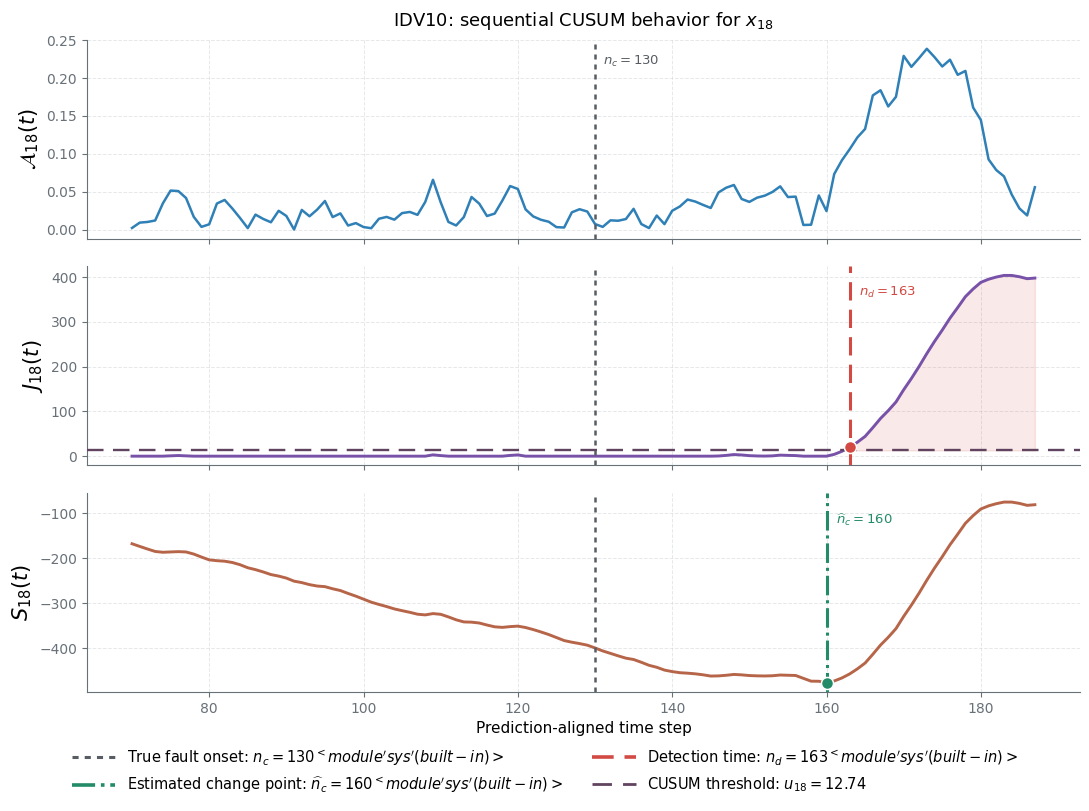

In [84]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ============================================================
# CUSUM VISUALIZATION
#
# Run after:
#     n_d, n_c, S, G = Vectorized_CUSUM(...)
# ============================================================

scenario_name = "IDV10"
fault_onset_time = 130
burn_in = 30

# ============================================================
# 1. IDENTIFY THE SENSOR RESPONSIBLE FOR THE EARLIEST ALARM
# ============================================================

detected_sensors = np.where(~np.isnan(n_d))[0]

if detected_sensors.size == 0:
    raise ValueError(
        f"No sensor-specific CUSUM alarm was generated for {scenario_name}."
    )

sensor = int(
    detected_sensors[
        np.argmin(n_d[detected_sensors])
    ]
)

variable_number = sensor + 1

detection_time = int(n_d[sensor])

if np.isnan(n_c[sensor]):
    raise ValueError(
        f"No change point was estimated for x_{variable_number}."
    )

estimated_change_time = int(n_c[sensor])

cusum_threshold = float(
    G_thresholds[sensor]
)

detection_delay = (
    detection_time
    - fault_onset_time
)

change_point_error = abs(
    estimated_change_time
    - fault_onset_time
)

print("=" * 62)
print(f"Scenario: {scenario_name}")
print(
    f"Sensor responsible for the earliest alarm: "
    f"x_{variable_number}"
)
print(f"True fault onset: n_c = {fault_onset_time}")
print(
    f"Estimated change point: "
    f"n_c_hat = {estimated_change_time}"
)
print(
    f"System-level detection time: "
    f"n_d = {detection_time}"
)
print(
    f"Detection delay: "
    f"D_det = {detection_delay}"
)
print(
    f"Absolute change-point estimation error: "
    f"E_cp = {change_point_error}"
)
print(
    f"CUSUM threshold: "
    f"u_{variable_number} = {cusum_threshold:.2f}"
)
print("=" * 62)

# ============================================================
# 2. SELECT THE DISPLAYED TIME INTERVAL
# ============================================================

plot_start = max(
    burn_in,
    fault_onset_time - 60
)

plot_end = min(
    a.shape[0],
    max(
        detection_time + 25,
        fault_onset_time + 50
    )
)

time_axis = np.arange(
    plot_start,
    plot_end
)

residual_values = a[
    plot_start:plot_end,
    sensor
]

J_values = G[
    plot_start:plot_end,
    sensor
]

S_values = S[
    plot_start:plot_end,
    sensor
]

# ============================================================
# 3. VISUAL SETTINGS
# ============================================================

COLOR_RESIDUAL = "#2F80B7"
COLOR_J = "#7851A9"
COLOR_S = "#B66549"

COLOR_FAULT = "#575D63"
COLOR_CHANGE = "#238B67"
COLOR_DETECTION = "#D24A43"
COLOR_THRESHOLD = "#60435F"

GRID_COLOR = "#C7CCD1"
AXIS_COLOR = "#687078"

LABEL_SIZE = 15

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(11, 8.2),
    sharex=True
)

ax_residual, ax_J, ax_S = axes

# ============================================================
# 4. PANEL 1
# ============================================================

ax_residual.plot(
    time_axis,
    residual_values,
    color=COLOR_RESIDUAL,
    linewidth=1.8
)

ax_residual.set_ylabel(
    rf"$\mathcal{{A}}_{{{variable_number}}}(t)$",
    fontsize=LABEL_SIZE
)

ax_residual.set_title(
    rf"{scenario_name}: sequential CUSUM behavior for "
    rf"$x_{{{variable_number}}}$",
    fontsize=13,
    pad=10
)

ax_residual.axvline(
    x=fault_onset_time,
    color=COLOR_FAULT,
    linestyle=(0, (2, 2)),
    linewidth=1.8,
    zorder=5
)

ax_residual.annotate(
    rf"$n_c={fault_onset_time}$",
    xy=(
        fault_onset_time,
        0.93
    ),
    xycoords=(
        "data",
        "axes fraction"
    ),
    xytext=(6, 0),
    textcoords="offset points",
    ha="left",
    va="top",
    color=COLOR_FAULT,
    fontsize=9.5,
    zorder=10
)

# ============================================================
# 5. PANEL 2
# ============================================================

ax_J.plot(
    time_axis,
    J_values,
    color=COLOR_J,
    linewidth=2.1
)

ax_J.axhline(
    y=cusum_threshold,
    color=COLOR_THRESHOLD,
    linestyle=(0, (7, 4)),
    linewidth=1.7,
    zorder=3
)

ax_J.axvline(
    x=fault_onset_time,
    color=COLOR_FAULT,
    linestyle=(0, (2, 2)),
    linewidth=1.8,
    zorder=4
)

ax_J.axvline(
    x=detection_time,
    color=COLOR_DETECTION,
    linestyle=(0, (6, 3)),
    linewidth=2.2,
    zorder=6
)

ax_J.fill_between(
    time_axis,
    J_values,
    cusum_threshold,
    where=(J_values >= cusum_threshold),
    color=COLOR_DETECTION,
    alpha=0.12,
    interpolate=True
)

ax_J.scatter(
    detection_time,
    G[detection_time, sensor],
    s=75,
    color=COLOR_DETECTION,
    edgecolor="white",
    linewidth=1.1,
    zorder=8
)

ax_J.annotate(
    rf"$n_d={detection_time}$",
    xy=(
        detection_time,
        0.91
    ),
    xycoords=(
        "data",
        "axes fraction"
    ),
    xytext=(7, 0),
    textcoords="offset points",
    ha="left",
    va="top",
    color=COLOR_DETECTION,
    fontsize=9.5,
    fontweight="bold",
    zorder=10
)

ax_J.set_ylabel(
    rf"$J_{{{variable_number}}}(t)$",
    fontsize=LABEL_SIZE
)

# ============================================================
# 6. PANEL 3
# ============================================================

ax_S.plot(
    time_axis,
    S_values,
    color=COLOR_S,
    linewidth=2.1
)

ax_S.axvline(
    x=fault_onset_time,
    color=COLOR_FAULT,
    linestyle=(0, (2, 2)),
    linewidth=1.8,
    zorder=4
)

ax_S.axvline(
    x=estimated_change_time,
    color=COLOR_CHANGE,
    linestyle="-.",
    linewidth=2.2,
    zorder=6
)

ax_S.scatter(
    estimated_change_time,
    S[estimated_change_time, sensor],
    s=75,
    color=COLOR_CHANGE,
    edgecolor="white",
    linewidth=1.1,
    zorder=8
)

ax_S.annotate(
    rf"$\widehat{{n}}_c={estimated_change_time}$",
    xy=(
        estimated_change_time,
        0.91
    ),
    xycoords=(
        "data",
        "axes fraction"
    ),
    xytext=(7, 0),
    textcoords="offset points",
    ha="left",
    va="top",
    color=COLOR_CHANGE,
    fontsize=9.5,
    fontweight="bold",
    zorder=10
)

ax_S.set_ylabel(
    rf"$S_{{{variable_number}}}(t)$",
    fontsize=LABEL_SIZE
)

ax_S.set_xlabel(
    "Prediction-aligned time step",
    fontsize=11
)

# ============================================================
# 7. GENERAL STYLING
# ============================================================

for ax in axes:

    ax.grid(
        True,
        which="major",
        color=GRID_COLOR,
        linestyle="--",
        linewidth=0.7,
        alpha=0.45
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_color(
        AXIS_COLOR
    )

    ax.spines["bottom"].set_color(
        AXIS_COLOR
    )

    ax.tick_params(
        axis="both",
        colors=AXIS_COLOR,
        labelsize=10
    )

# ============================================================
# 8. COMMON LEGEND
# ============================================================

legend_handles = [

    Line2D(
        [0],
        [0],
        color=COLOR_FAULT,
        linestyle=(0, (2, 2)),
        linewidth=2.2,
        label=rf"True fault onset: $n_c={fault_onset_time}^{sys}$"
    ),

    Line2D(
        [0],
        [0],
        color=COLOR_CHANGE,
        linestyle="-.",
        linewidth=2.6,
        label=rf"Estimated change point: $\widehat{{n}}_c={estimated_change_time}^{sys}$"
    ),

    Line2D(
        [0],
        [0],
        color=COLOR_DETECTION,
        linestyle=(0, (6, 3)),
        linewidth=2.6,
        label=rf"Detection time: $n_d={detection_time}^{sys}$"
    ),

    Line2D(
        [0],
        [0],
        color=COLOR_THRESHOLD,
        linestyle=(0, (7, 4)),
        linewidth=2.0,
        label=rf"CUSUM threshold: $u_{{{variable_number}}}={cusum_threshold:.2f}$"
    ),
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.008),
    ncol=2,
    frameon=False,
    fontsize=10.5,
    handlelength=3.0,
    handletextpad=0.8,
)

# ============================================================
# 9. FINAL LAYOUT
# ============================================================

plt.tight_layout(
    rect=[0, 0.11, 1, 1]
)

fig.subplots_adjust(
    hspace=0.14,
    bottom=0.15
)

safe_scenario_name = (
    scenario_name
    .lower()
    .replace(" ", "_")
)

plt.savefig(
    f"{safe_scenario_name}_cusum_example.pdf",
    bbox_inches="tight"
)

plt.savefig(
    f"{safe_scenario_name}_cusum_example.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Scenario: IDV14
Detection sensor: x_21 (xmeas_21, Python index 20)
Change-point sensor: x_32 (xmv_10, Python index 31)
Same sensor: False
True fault onset: n_c = 130
System-level detection time: n_d^sys = 130
System-level estimated change point: n_c_hat^sys = 126
Detection delay: D_det = 0
Absolute change-point error: E_cp = 4
CUSUM threshold: u_21 = 9.711949


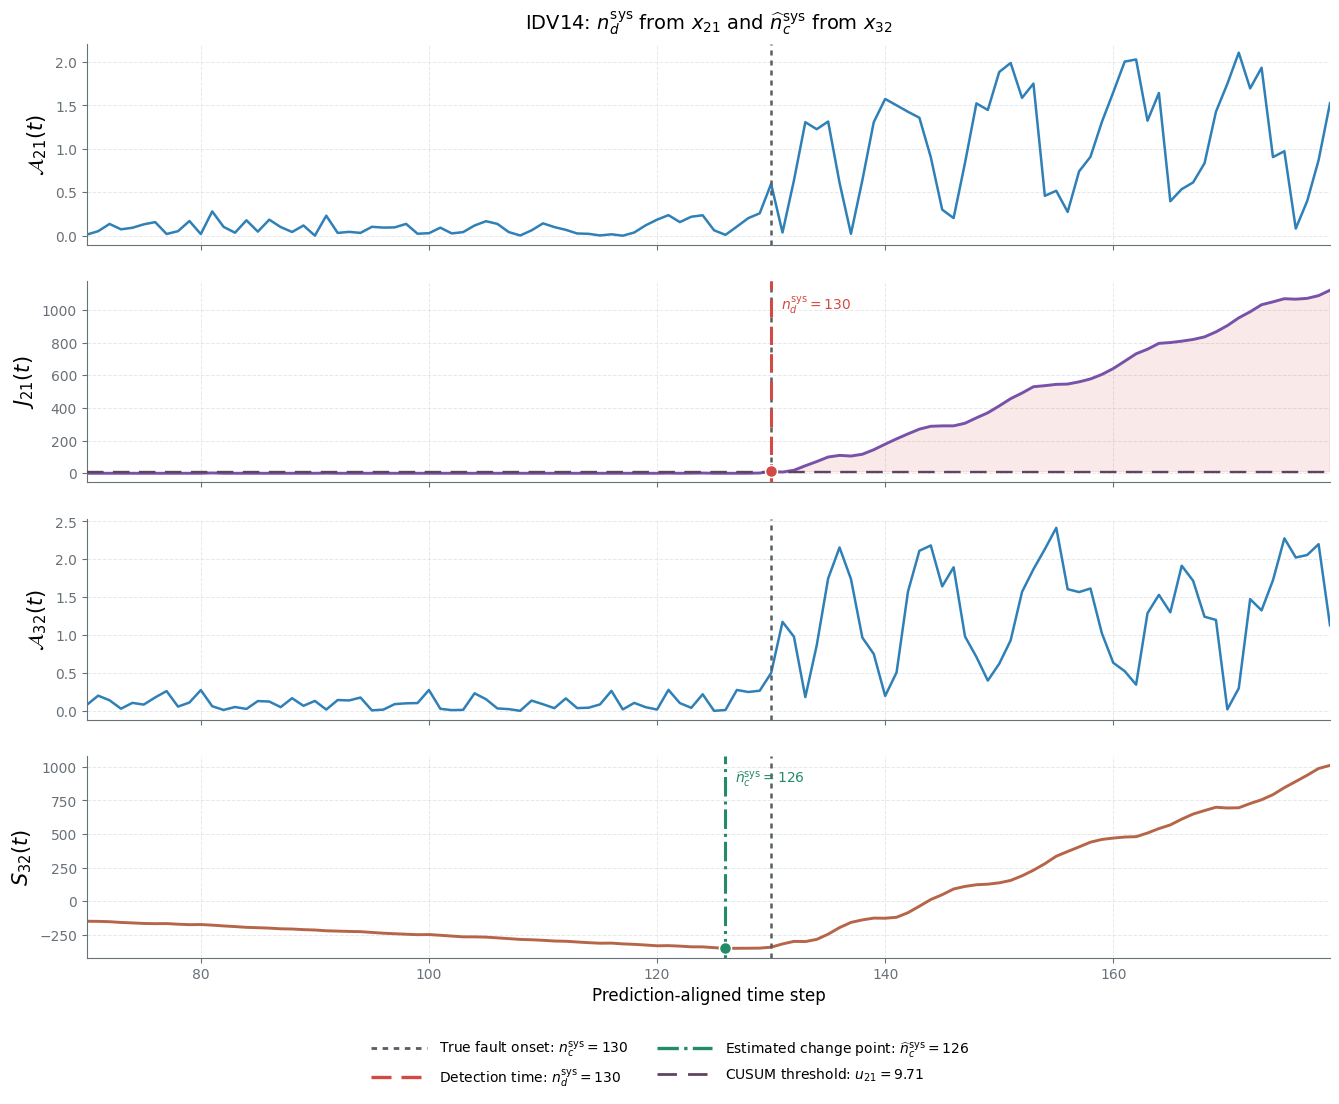

In [94]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ============================================================
# SETTINGS
# ============================================================

scenario_name = "IDV14"

fault_onset_time = 130
burn_in = 30

# ============================================================
# INPUT ARRAYS
# ============================================================

a = np.asarray(
    a,
    dtype=float,
)

G = np.asarray(
    G,
    dtype=float,
)

S = np.asarray(
    S,
    dtype=float,
)

n_d = np.asarray(
    n_d,
    dtype=float,
).reshape(-1)

n_c = np.asarray(
    n_c,
    dtype=float,
).reshape(-1)

G_thresholds = np.asarray(
    G_thresholds,
    dtype=float,
).reshape(-1)

# ============================================================
# INPUT CHECKS
# ============================================================

if a.ndim != 2:
    raise ValueError(
        "a must have shape (n_steps, n_sensors). "
        f"Received shape: {a.shape}"
    )

if G.shape != a.shape:
    raise ValueError(
        "G and a must have the same shape. "
        f"a.shape={a.shape}, G.shape={G.shape}"
    )

if S.shape != a.shape:
    raise ValueError(
        "S and a must have the same shape. "
        f"a.shape={a.shape}, S.shape={S.shape}"
    )

number_of_sensors = a.shape[1]

if n_d.size != number_of_sensors:
    raise ValueError(
        "n_d must contain one value per sensor."
    )

if n_c.size != number_of_sensors:
    raise ValueError(
        "n_c must contain one value per sensor."
    )

if G_thresholds.size != number_of_sensors:
    raise ValueError(
        "G_thresholds must contain one value per sensor."
    )

# ============================================================
# SENSOR RESPONSIBLE FOR SYSTEM-LEVEL DETECTION
#
# i_d = argmin_i n_d,i
# ============================================================

valid_detection = np.where(
    np.isfinite(n_d)
)[0]

if valid_detection.size == 0:
    raise ValueError(
        f"No CUSUM detection was generated for {scenario_name}."
    )

sensor_detection = int(
    valid_detection[
        np.argmin(
            n_d[valid_detection]
        )
    ]
)

detection_time = int(
    n_d[sensor_detection]
)

# ============================================================
# SENSOR RESPONSIBLE FOR SYSTEM-LEVEL CHANGE-POINT ESTIMATE
#
# i_c = argmin_i n_c_hat,i
# ============================================================

valid_change = np.where(
    np.isfinite(n_c)
)[0]

if valid_change.size == 0:
    raise ValueError(
        f"No change-point estimate was obtained for "
        f"{scenario_name}."
    )

sensor_change = int(
    valid_change[
        np.argmin(
            n_c[valid_change]
        )
    ]
)

estimated_change_time = int(
    n_c[sensor_change]
)

# ============================================================
# SENSOR INFORMATION
# ============================================================

# Python index 0 corresponds to thesis notation x_1.
var_det = sensor_detection + 1
var_cp = sensor_change + 1

u_det = float(
    G_thresholds[sensor_detection]
)

same_sensor = bool(
    sensor_detection
    ==
    sensor_change
)

# Optional original TEP variable names.
if (
    "var_list" in globals()
    and var_list is not None
    and len(var_list) == number_of_sensors
):
    original_name_detection = str(
        var_list[sensor_detection]
    )

    original_name_change = str(
        var_list[sensor_change]
    )

else:
    original_name_detection = (
        f"sensor_{sensor_detection}"
    )

    original_name_change = (
        f"sensor_{sensor_change}"
    )

# ============================================================
# METRICS
# ============================================================

detection_delay = (
    detection_time
    - fault_onset_time
)

change_point_error = abs(
    estimated_change_time
    - fault_onset_time
)

# ============================================================
# PRINT SUMMARY
# ============================================================

print("=" * 72)

print(
    f"Scenario: {scenario_name}"
)

print(
    "Detection sensor: "
    f"x_{var_det} "
    f"({original_name_detection}, "
    f"Python index {sensor_detection})"
)

print(
    "Change-point sensor: "
    f"x_{var_cp} "
    f"({original_name_change}, "
    f"Python index {sensor_change})"
)

print(
    f"Same sensor: {same_sensor}"
)

print(
    f"True fault onset: n_c = {fault_onset_time}"
)

print(
    f"System-level detection time: "
    f"n_d^sys = {detection_time}"
)

print(
    f"System-level estimated change point: "
    f"n_c_hat^sys = {estimated_change_time}"
)

print(
    f"Detection delay: D_det = {detection_delay}"
)

print(
    f"Absolute change-point error: "
    f"E_cp = {change_point_error}"
)

print(
    f"CUSUM threshold: "
    f"u_{var_det} = {u_det:.6f}"
)

print("=" * 72)

# ============================================================
# DISPLAY WINDOW
# ============================================================

plot_start = max(
    burn_in,
    fault_onset_time - 60,
)

plot_end = min(
    a.shape[0],
    max(
        detection_time + 25,
        estimated_change_time + 25,
        fault_onset_time + 50,
    ),
)

if plot_end <= plot_start:
    raise ValueError(
        "Invalid plotting interval: "
        f"plot_start={plot_start}, "
        f"plot_end={plot_end}."
    )

time_axis = np.arange(
    plot_start,
    plot_end,
)

# ============================================================
# DISPLAYED TRAJECTORIES
# ============================================================

A_detection_values = a[
    plot_start:plot_end,
    sensor_detection,
]

J_detection_values = G[
    plot_start:plot_end,
    sensor_detection,
]

A_change_values = a[
    plot_start:plot_end,
    sensor_change,
]

S_change_values = S[
    plot_start:plot_end,
    sensor_change,
]

# ============================================================
# COLORS AND STYLES
# ============================================================

COLOR_RESIDUAL = "#2F80B7"
COLOR_J = "#7851A9"
COLOR_S = "#B66549"

COLOR_FAULT = "#575D63"
COLOR_CHANGE = "#238B67"
COLOR_DETECTION = "#D24A43"
COLOR_THRESHOLD = "#60435F"

GRID_COLOR = "#C7CCD1"
AXIS_COLOR = "#687078"

FAULT_LINESTYLE = (
    0,
    (2, 2),
)

DETECTION_LINESTYLE = (
    0,
    (6, 3),
)

THRESHOLD_LINESTYLE = (
    0,
    (7, 4),
)

CHANGE_LINESTYLE = "-."

YLABEL_SIZE = 15
XLABEL_SIZE = 12
TITLE_SIZE = 14
TICK_SIZE = 10
LEGEND_SIZE = 10

# ============================================================
# DRAWING HELPERS
# ============================================================

def draw_true_onset(axis):
    """
    Draw the true change point.
    """

    axis.axvline(
        x=fault_onset_time,
        color=COLOR_FAULT,
        linestyle=FAULT_LINESTYLE,
        linewidth=1.8,
        zorder=4,
    )


def draw_detection_information(axis):
    """
    Draw the true onset, system-level detection time,
    threshold, and threshold-crossing point.
    """

    draw_true_onset(
        axis
    )

    axis.axvline(
        x=detection_time,
        color=COLOR_DETECTION,
        linestyle=DETECTION_LINESTYLE,
        linewidth=2.2,
        zorder=6,
    )

    axis.axhline(
        y=u_det,
        color=COLOR_THRESHOLD,
        linestyle=THRESHOLD_LINESTYLE,
        linewidth=1.7,
        zorder=3,
    )

    axis.scatter(
        detection_time,
        G[
            detection_time,
            sensor_detection,
        ],
        s=75,
        color=COLOR_DETECTION,
        edgecolor="white",
        linewidth=1.1,
        zorder=8,
    )

    # Label immediately next to the detection line.
    axis.annotate(
        (
            rf"$n_d^{{\mathrm{{sys}}}}"
            rf"={detection_time}$"
        ),
        xy=(
            detection_time,
            0.94,
        ),
        xycoords=(
            "data",
            "axes fraction",
        ),
        xytext=(
            7,
            0,
        ),
        textcoords="offset points",
        ha="left",
        va="top",
        color=COLOR_DETECTION,
        fontsize=10,
        fontweight="bold",
        zorder=10,
    )


def draw_change_point_information(axis):
    """
    Draw the true onset and system-level estimated
    change point.
    """

    draw_true_onset(
        axis
    )

    axis.axvline(
        x=estimated_change_time,
        color=COLOR_CHANGE,
        linestyle=CHANGE_LINESTYLE,
        linewidth=2.2,
        zorder=6,
    )

    axis.scatter(
        estimated_change_time,
        S[
            estimated_change_time,
            sensor_change,
        ],
        s=75,
        color=COLOR_CHANGE,
        edgecolor="white",
        linewidth=1.1,
        zorder=8,
    )

    # Label immediately next to the estimated change-point line.
    axis.annotate(
        (
            rf"$\widehat{{n}}_c^{{\mathrm{{sys}}}}"
            rf"={estimated_change_time}$"
        ),
        xy=(
            estimated_change_time,
            0.94,
        ),
        xycoords=(
            "data",
            "axes fraction",
        ),
        xytext=(
            7,
            0,
        ),
        textcoords="offset points",
        ha="left",
        va="top",
        color=COLOR_CHANGE,
        fontsize=10,
        fontweight="bold",
        zorder=10,
    )

# ============================================================
# CREATE FIGURE
# ============================================================

if same_sensor:

    fig, axes = plt.subplots(
        nrows=3,
        ncols=1,
        figsize=(13.5, 8.8),
        sharex=True,
    )

    (
        ax_A,
        ax_J,
        ax_S,
    ) = axes

    # --------------------------------------------------------
    # PANEL 1: RESIDUAL
    # --------------------------------------------------------

    ax_A.plot(
        time_axis,
        A_detection_values,
        color=COLOR_RESIDUAL,
        linewidth=1.8,
    )

    ax_A.set_ylabel(
        rf"$\mathcal{{A}}_{{{var_det}}}(t)$",
        fontsize=YLABEL_SIZE,
    )

    ax_A.set_title(
        rf"{scenario_name}: sequential CUSUM behavior for "
        rf"$x_{{{var_det}}}$",
        fontsize=TITLE_SIZE,
        pad=10,
    )

    # Only the true onset is shown on residual panels.
    draw_true_onset(
        ax_A
    )

    # --------------------------------------------------------
    # PANEL 2: ALARM STATISTIC
    # --------------------------------------------------------

    ax_J.plot(
        time_axis,
        J_detection_values,
        color=COLOR_J,
        linewidth=2.1,
    )

    ax_J.fill_between(
        time_axis,
        J_detection_values,
        u_det,
        where=(
            J_detection_values
            >= u_det
        ),
        color=COLOR_DETECTION,
        alpha=0.12,
        interpolate=True,
    )

    ax_J.set_ylabel(
        rf"$J_{{{var_det}}}(t)$",
        fontsize=YLABEL_SIZE,
    )

    draw_detection_information(
        ax_J
    )

    # --------------------------------------------------------
    # PANEL 3: HISTORY TRACKER
    # --------------------------------------------------------

    ax_S.plot(
        time_axis,
        S_change_values,
        color=COLOR_S,
        linewidth=2.1,
    )

    ax_S.set_ylabel(
        rf"$S_{{{var_cp}}}(t)$",
        fontsize=YLABEL_SIZE,
    )

    ax_S.set_xlabel(
        "Prediction-aligned time step",
        fontsize=XLABEL_SIZE,
    )

    draw_change_point_information(
        ax_S
    )

else:

    fig, axes = plt.subplots(
        nrows=4,
        ncols=1,
        figsize=(13.5, 11.2),
        sharex=True,
    )

    (
        ax_A_detection,
        ax_J,
        ax_A_change,
        ax_S,
    ) = axes

    # --------------------------------------------------------
    # PANEL 1: RESIDUAL OF DETECTION SENSOR
    # --------------------------------------------------------

    ax_A_detection.plot(
        time_axis,
        A_detection_values,
        color=COLOR_RESIDUAL,
        linewidth=1.8,
    )

    ax_A_detection.set_ylabel(
        rf"$\mathcal{{A}}_{{{var_det}}}(t)$",
        fontsize=YLABEL_SIZE,
    )

    ax_A_detection.set_title(
        rf"{scenario_name}: "
        rf"$n_d^{{\mathrm{{sys}}}}$ from "
        rf"$x_{{{var_det}}}$ and "
        rf"$\widehat{{n}}_c^{{\mathrm{{sys}}}}$ from "
        rf"$x_{{{var_cp}}}$",
        fontsize=TITLE_SIZE,
        pad=10,
    )

    # Only true onset on residual panel.
    draw_true_onset(
        ax_A_detection
    )

    # --------------------------------------------------------
    # PANEL 2: J OF DETECTION SENSOR
    # --------------------------------------------------------

    ax_J.plot(
        time_axis,
        J_detection_values,
        color=COLOR_J,
        linewidth=2.1,
    )

    ax_J.fill_between(
        time_axis,
        J_detection_values,
        u_det,
        where=(
            J_detection_values
            >= u_det
        ),
        color=COLOR_DETECTION,
        alpha=0.12,
        interpolate=True,
    )

    ax_J.set_ylabel(
        rf"$J_{{{var_det}}}(t)$",
        fontsize=YLABEL_SIZE,
    )

    draw_detection_information(
        ax_J
    )

    # --------------------------------------------------------
    # PANEL 3: RESIDUAL OF CHANGE-POINT SENSOR
    # --------------------------------------------------------

    ax_A_change.plot(
        time_axis,
        A_change_values,
        color=COLOR_RESIDUAL,
        linewidth=1.8,
    )

    ax_A_change.set_ylabel(
        rf"$\mathcal{{A}}_{{{var_cp}}}(t)$",
        fontsize=YLABEL_SIZE,
    )

    # Only true onset on residual panel.
    draw_true_onset(
        ax_A_change
    )

    # --------------------------------------------------------
    # PANEL 4: S OF CHANGE-POINT SENSOR
    # --------------------------------------------------------

    ax_S.plot(
        time_axis,
        S_change_values,
        color=COLOR_S,
        linewidth=2.1,
    )

    ax_S.set_ylabel(
        rf"$S_{{{var_cp}}}(t)$",
        fontsize=YLABEL_SIZE,
    )

    ax_S.set_xlabel(
        "Prediction-aligned time step",
        fontsize=XLABEL_SIZE,
    )

    draw_change_point_information(
        ax_S
    )

# ============================================================
# GENERAL AXIS STYLING
# ============================================================

for axis in axes:

    axis.grid(
        True,
        which="major",
        color=GRID_COLOR,
        linestyle="--",
        linewidth=0.7,
        alpha=0.45,
    )

    axis.set_axisbelow(
        True
    )

    axis.spines[
        "top"
    ].set_visible(
        False
    )

    axis.spines[
        "right"
    ].set_visible(
        False
    )

    axis.spines[
        "left"
    ].set_color(
        AXIS_COLOR
    )

    axis.spines[
        "bottom"
    ].set_color(
        AXIS_COLOR
    )

    axis.tick_params(
        axis="both",
        colors=AXIS_COLOR,
        labelsize=TICK_SIZE,
    )

    axis.set_xlim(
        plot_start,
        plot_end - 1,
    )

# ============================================================
# COMMON BOTTOM LEGEND
# ============================================================

legend_handles = [
    Line2D(
        [0],
        [0],
        color=COLOR_FAULT,
        linestyle=FAULT_LINESTYLE,
        linewidth=2.0,
        label=(
            rf"True fault onset: "
            rf"$n_c^{{\mathrm{{sys}}}}={fault_onset_time}$"
        ),
    ),
    Line2D(
        [0],
        [0],
        color=COLOR_DETECTION,
        linestyle=DETECTION_LINESTYLE,
        linewidth=2.4,
        label=(
            rf"Detection time: "
            rf"$n_d^{{\mathrm{{sys}}}}"
            rf"={detection_time}$"
        ),
    ),
    Line2D(
        [0],
        [0],
        color=COLOR_CHANGE,
        linestyle=CHANGE_LINESTYLE,
        linewidth=2.4,
        label=(
            rf"Estimated change point: "
            rf"$\widehat{{n}}_c^{{\mathrm{{sys}}}}"
            rf"={estimated_change_time}$"
        ),
    ),
    Line2D(
        [0],
        [0],
        color=COLOR_THRESHOLD,
        linestyle=THRESHOLD_LINESTYLE,
        linewidth=2.0,
        label=(
            rf"CUSUM threshold: "
            rf"$u_{{{var_det}}}={u_det:.2f}$"
        ),
    ),
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(
        0.5,
        0.012,
    ),
    ncol=2,
    frameon=False,
    fontsize=LEGEND_SIZE,
    handlelength=4.0,
    handletextpad=0.9,
    columnspacing=2.0,
)

# ============================================================
# FINAL LAYOUT
# ============================================================

plt.tight_layout(
    rect=[
        0,
        0.105,
        1,
        1,
    ]
)

fig.subplots_adjust(
    hspace=0.18,
    bottom=0.14,
)


In [64]:
parameter_summary.to_csv(
    "idv19_corrected_cusum_sensor_summary.csv",
    index=False,
)

arl_diagnostics.to_csv(
    "idv19_corrected_cusum_arl_diagnostics.csv",
    index=False,
)
